In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# Mendukung struktur proyek asli dan file CSV yang disertakan bersama notebook.
kemungkinan_path = [
    Path.cwd() / "data" / "tabel_durasi.csv",
    Path.cwd().parent.parent / "data" / "tabel_durasi.csv",
    Path.cwd() / "tabel_durasi.csv",
    Path("/mnt/data/tabel_durasi(1).csv"),  # fallback untuk berkas unggahan
]
file_path = next((p for p in kemungkinan_path if p.exists()), None)
if file_path is None:
    raise FileNotFoundError(
        "CSV tidak ditemukan. Letakkan tabel_durasi.csv di folder data/ "
        "atau di folder yang sama dengan notebook."
    )

df = pd.read_csv(file_path, encoding="utf-8")
print(f"Sumber data: {file_path}")
print(f"Jumlah catatan: {len(df)}")
display(df.head())

Sumber data: /mnt/data/kantin_update_package/data/tabel_durasi.csv
Jumlah catatan: 77


,Durasi,Hari,Waktu
0,53 detik,Jumat,JAM 10
1,1 menit 50 detik,Jumat,JAM 10
2,1 menit 6 detik,Jumat,JAM 10
3,47 detik,Selasa,JAM 10
4,20 detik,Selasa,JAM 10


In [2]:
def konversi_durasi(teks):
    teks = str(teks).lower().strip()

    menit = re.search(r'(\d+)\s*menit', teks)
    detik = re.search(r'(\d+)\s*detik', teks)

    total_detik = 0

    if menit:
        total_detik += int(menit.group(1)) * 60

    if detik:
        total_detik += int(detik.group(1))

    return total_detik

df["Durasi"] = df["Durasi"].apply(konversi_durasi)
print(df.head())

   Durasi    Hari   Waktu
0      53   Jumat  JAM 10
1     110   Jumat  JAM 10
2      66   Jumat  JAM 10
3      47  Selasa  JAM 10
4      20  Selasa  JAM 10


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Durasi  77 non-null     int64 
 1   Hari    77 non-null     object
 2   Waktu   77 non-null     object
dtypes: int64(1), object(2)
memory usage: 1.9+ KB


In [4]:
q1 = np.percentile(df["Durasi"], 25)
q3 = np.percentile(df["Durasi"], 75)
iqr = q3 - q1
batas_wajar = q3 + (1.5 * iqr)
print(f"Batas wajar: {batas_wajar}, IQR: {iqr}, Q1: {q1}, Q3: {q3}")

Batas wajar: 396.0, IQR: 134.0, Q1: 61.0, Q3: 195.0


In [5]:
import numpy as np

q1 = np.percentile(df["Durasi"], 25)
q3 = np.percentile(df["Durasi"], 75)
iqr = q3 - q1

batas_atas = q3 + (1.5 * iqr)
batas_bawah = q1 - (1.5 * iqr)

print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")
print(f"Batas bawah: {batas_bawah}")
print(f"Batas atas : {batas_atas}")

outlier = df[(df["Durasi"] < batas_bawah) | (df["Durasi"] > batas_atas)]

print(f"\nJumlah outlier: {len(outlier)}")
print(outlier[["Durasi"]])  # atau kolom lain yang relevan

Q1: 61.0
Q3: 195.0
IQR: 134.0
Batas bawah: -140.0
Batas atas : 396.0

Jumlah outlier: 6
    Durasi
34     530
42     518
51     508
57     482
64     500
65     492


In [6]:
# Empat kandidat distribusi: normal, uniform, log-normal, dan eksponensial.
# Untuk distribusi yang hanya bernilai positif, log-normal dan eksponensial
# menggunakan loc=0 (tanpa pergeseran parameter lokasi).
def fit_normal(data):
    return stats.norm.fit(data)  # loc=mean, scale=simpangan baku MLE


def fit_uniform(data):
    return stats.uniform.fit(data)  # loc=min(data), scale=max(data)-min(data)


def fit_lognormal(data):
    return stats.lognorm.fit(data, floc=0)  # shape=sigma, loc=0, scale


def fit_eksponensial(data):
    return stats.expon.fit(data, floc=0)  # loc=0, scale=rata-rata


model_specs = [
    {
        "nama": "Normal",
        "dist": stats.norm,
        "fit": fit_normal,
        "parameter_nama": ["mean/loc", "std/scale"],
        "k": 2,
    },
    {
        "nama": "Uniform",
        "dist": stats.uniform,
        "fit": fit_uniform,
        "parameter_nama": ["loc/min", "scale/rentang"],
        "k": 2,
    },
    {
        "nama": "Log-normal",
        "dist": stats.lognorm,
        "fit": fit_lognormal,
        "parameter_nama": ["shape/sigma", "loc", "scale"],
        "k": 2,  # loc ditetapkan 0; shape dan scale diestimasi
    },
    {
        "nama": "Eksponensial",
        "dist": stats.expon,
        "fit": fit_eksponensial,
        "parameter_nama": ["loc", "scale"],
        "k": 1,  # loc ditetapkan 0; hanya scale diestimasi
    },
]

In [7]:
# KS p-value dihitung dengan parametric bootstrap agar proses estimasi parameter
# ikut diperhitungkan. Nilai p bukan probabilitas bahwa distribusi pasti benar.
x_data = df["Durasi"].to_numpy(dtype=float)
n = len(x_data)
B_BOOTSTRAP = 2000

hasil_uji = []
for i_model, spec in enumerate(model_specs):
    dist = spec["dist"]
    params = spec["fit"](x_data)
    loglik = float(np.sum(dist.logpdf(x_data, *params)))
    ks_stat = float(stats.kstest(x_data, dist.cdf, args=params).statistic)
    aic = 2 * spec["k"] - 2 * loglik
    bic = np.log(n) * spec["k"] - 2 * loglik

    # Bootstrap terpisah dengan seed tetap untuk setiap distribusi.
    rng_bootstrap = np.random.default_rng(42 + i_model)
    ks_boot = np.empty(B_BOOTSTRAP)
    for b in range(B_BOOTSTRAP):
        simulasi_boot = dist.rvs(*params, size=n, random_state=rng_bootstrap)
        params_boot = spec["fit"](simulasi_boot)
        ks_boot[b] = stats.kstest(
            simulasi_boot, dist.cdf, args=params_boot
        ).statistic
    p_boot = (1 + np.count_nonzero(ks_boot >= ks_stat)) / (B_BOOTSTRAP + 1)

    params_text = ", ".join(
        f"{nama}={nilai:.4f}"
        for nama, nilai in zip(spec["parameter_nama"], params)
    )
    hasil_uji.append({
        "nama": spec["nama"], "dist": dist, "fit": spec["fit"],
        "params": params, "params_text": params_text,
        "k": spec["k"], "loglik": loglik, "aic": aic, "bic": bic,
        "ks": ks_stat, "p_boot": p_boot,
    })

hasil_tabel = pd.DataFrame([
    {
        "Distribusi": h["nama"],
        "Parameter hasil fit": h["params_text"],
        "Log-likelihood": h["loglik"],
        "AIC": h["aic"],
        "BIC": h["bic"],
        "KS D": h["ks"],
        "p-value bootstrap KS": h["p_boot"],
    }
    for h in hasil_uji
]).sort_values("AIC").reset_index(drop=True)

print(f"Perbandingan empat distribusi untuk {n} catatan; bootstrap KS = {B_BOOTSTRAP:,} replikasi.")
print(hasil_tabel.round(4).to_string(index=False))

terbaik = min(hasil_uji, key=lambda h: h["aic"])
model_normal = next(h for h in hasil_uji if h["nama"] == "Normal")
model_uniform = next(h for h in hasil_uji if h["nama"] == "Uniform")
model_lognormal = next(h for h in hasil_uji if h["nama"] == "Log-normal")
model_expon = next(h for h in hasil_uji if h["nama"] == "Eksponensial")

print("\nKesimpulan perbandingan:")
print(f"- AIC terendah: {terbaik['nama']} (AIC = {terbaik['aic']:.2f}).")
print(f"- Log-normal: KS D = {model_lognormal['ks']:.4f}; p bootstrap = {model_lognormal['p_boot']:.4f}.")
print(f"- Eksponensial: KS D = {model_expon['ks']:.4f}; p bootstrap = {model_expon['p_boot']:.4f}.")
print(f"- Normal: KS D = {model_normal['ks']:.4f}; p bootstrap = {model_normal['p_boot']:.4f}.")
print(f"- Uniform: KS D = {model_uniform['ks']:.4f}; p bootstrap = {model_uniform['p_boot']:.4f}.")
print("Interpretasi: log-normal paling sesuai dari empat kandidat berdasarkan AIC terendah dan KS D terkecil.")
print("Normal, uniform, dan eksponensial standar tidak lolos pemeriksaan bootstrap KS pada taraf 5%; hasil ini tetap bukan kepastian bahwa log-normal adalah distribusi yang benar.")

Perbandingan empat distribusi untuk 77 catatan; bootstrap KS = 2,000 replikasi.
  Distribusi                            Parameter hasil fit  Log-likelihood      AIC      BIC   KS D  p-value bootstrap KS
  Log-normal shape/sigma=0.8101, loc=0.0000, scale=111.1419       -455.7740 915.5479 920.2355 0.0647                0.6037
Eksponensial                     loc=0.0000, scale=153.2338       -464.4613 930.9226 933.2664 0.1748                0.0010
     Uniform        loc/min=14.0000, scale/rentang=516.0000       -480.9502 965.9004 970.5881 0.4188                0.0005
      Normal          mean/loc=153.2338, std/scale=129.7343       -483.9009 971.8017 976.4894 0.1835                0.0005

Kesimpulan perbandingan:
- AIC terendah: Log-normal (AIC = 915.55).
- Log-normal: KS D = 0.0647; p bootstrap = 0.6037.
- Eksponensial: KS D = 0.1748; p bootstrap = 0.0010.
- Normal: KS D = 0.1835; p bootstrap = 0.0005.
- Uniform: KS D = 0.4188; p bootstrap = 0.0005.
Interpretasi: log-normal paling sesua

## Perbandingan Diagnostik Empat Distribusi

Durasi adalah **lama seseorang berada di kantin**, bukan waktu layanan. Analisis membandingkan empat kandidat: **normal**, **uniform**, **log-normal**, dan **eksponensial standar**. Model log-normal dan eksponensial memakai `loc=0`, sehingga keduanya tidak menggunakan pergeseran lokasi.

- **AIC/BIC lebih kecil** menunjukkan model yang lebih disukai dengan mempertimbangkan kecocokan dan jumlah parameter.
- **Statistik KS D lebih kecil** berarti kurva distribusi kumulatif model lebih dekat ke distribusi empiris.
- **p-value bootstrap KS** dihitung melalui 2.000 simulasi untuk setiap model dengan estimasi ulang parameter pada tiap replikasi.

Kriteria-kriteria tersebut saling melengkapi. AIC memilih kompromi antara kecocokan dan kompleksitas, sementara KS mengukur jarak maksimum antarkurva kumulatif. p-value bootstrap membantu menilai apakah penyimpangan sebanding dengan yang dapat dihasilkan model, tetapi tidak membuktikan bahwa suatu distribusi pasti benar.

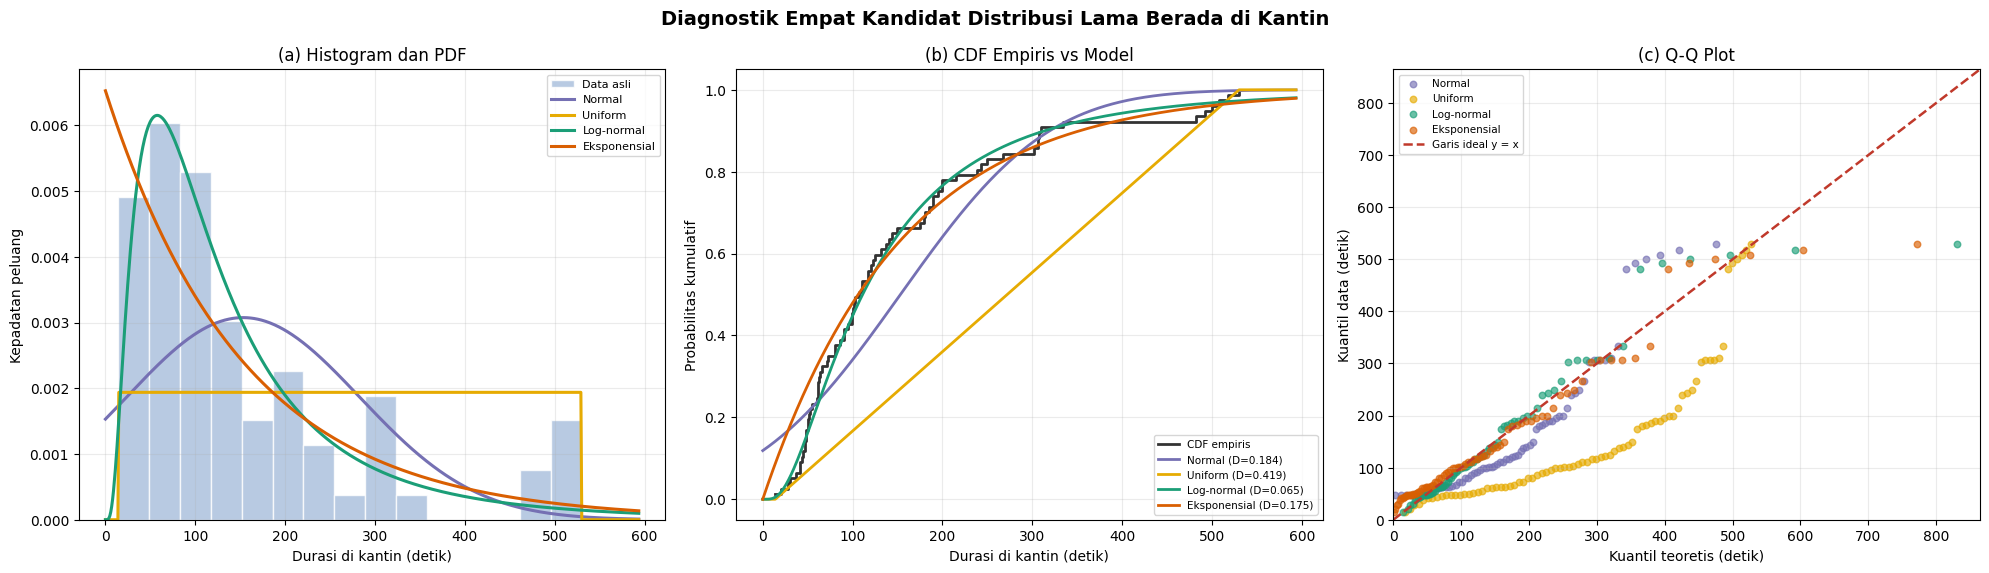

In [8]:
# Visualisasi kecocokan empat distribusi
n = len(x_data)
x_grid = np.linspace(0, max(x_data) * 1.12, 600)
x_sorted = np.sort(x_data)
ecdf = np.arange(1, n + 1) / n

warna_model = {
    "Normal": "#7570b3",
    "Uniform": "#e6ab02",
    "Log-normal": "#1b9e77",
    "Eksponensial": "#d95f02",
}

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

# (a) Histogram dengan PDF keempat model
ax = axes[0]
ax.hist(x_data, bins=15, density=True, color="#a6bddb", edgecolor="white",
        alpha=0.8, label="Data asli")
for h in hasil_uji:
    color = warna_model[h["nama"]]
    ax.plot(x_grid, h["dist"].pdf(x_grid, *h["params"]), lw=2.2,
            color=color, label=h["nama"])
ax.set_title("(a) Histogram dan PDF")
ax.set_xlabel("Durasi di kantin (detik)")
ax.set_ylabel("Kepadatan peluang")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

# (b) CDF empiris dan CDF empat model
ax = axes[1]
ax.step(x_sorted, ecdf, where="post", color="#333333", lw=2,
        label="CDF empiris")
for h in hasil_uji:
    color = warna_model[h["nama"]]
    ax.plot(x_grid, h["dist"].cdf(x_grid, *h["params"]), lw=2,
            color=color, label=f"{h['nama']} (D={h['ks']:.3f})")
ax.set_title("(b) CDF Empiris vs Model")
ax.set_xlabel("Durasi di kantin (detik)")
ax.set_ylabel("Probabilitas kumulatif")
ax.legend(fontsize=7.5, loc="lower right")
ax.grid(alpha=0.25)

# (c) Q-Q plot untuk keempat model
ax = axes[2]
prob = (np.arange(1, n + 1) - 0.5) / n
qq_quantiles = []
for h in hasil_uji:
    color = warna_model[h["nama"]]
    q_theory = h["dist"].ppf(prob, *h["params"])
    qq_quantiles.extend(q_theory[np.isfinite(q_theory)].tolist())
    ax.scatter(q_theory, x_sorted, s=22, alpha=0.65, color=color,
               label=h["nama"])
max_axis = max(float(x_sorted.max()), max(qq_quantiles)) * 1.04
ax.plot([0, max_axis], [0, max_axis], color="#c0392b", ls="--", lw=1.8,
        label="Garis ideal y = x")
ax.set_xlim(0, max_axis)
ax.set_ylim(0, max_axis)
ax.set_title("(c) Q-Q Plot")
ax.set_xlabel("Kuantil teoretis (detik)")
ax.set_ylabel("Kuantil data (detik)")
ax.legend(fontsize=7.5, loc="upper left")
ax.grid(alpha=0.25)

fig.suptitle("Diagnostik Empat Kandidat Distribusi Lama Berada di Kantin", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

### Interpretasi Hasil Perbandingan

- **Log-normal menjadi model utama** dari empat kandidat karena memiliki AIC terendah dan statistik KS D terkecil. Parameter hasil fit dengan `loc=0` adalah `shape/sigma ≈ 0,8101` dan `scale ≈ 111,14` detik.
- **Eksponensial standar kurang sesuai**: model ini memiliki AIC lebih tinggi dan jarak KS lebih besar daripada log-normal. p-value bootstrap KS juga kecil pada taraf 5%.
- **Normal dan uniform lebih tidak sesuai** untuk data yang menceng ke kanan. Model normal kurang merepresentasikan ekor kanan, sedangkan uniform mengasumsikan kepadatan yang konstan pada intervalnya; keduanya memiliki statistik KS yang besar dan p-value bootstrap yang sangat kecil.
- **Hasil ini tidak membuktikan log-normal pasti benar.** Sampel berjumlah 77 dan terdapat celah data pada durasi sekitar 6–8 menit. Kesimpulan dibatasi pada empat kandidat yang dibandingkan dan metode fitting yang ditetapkan.

**Implikasi untuk simulasi:** gunakan distribusi log-normal hasil fit, `stats.lognorm.rvs(s=0.8101, loc=0, scale=111.14, size=n)`, sebagai model utama karena paling sesuai relatif terhadap tiga kandidat lain. Simulasi tetap hanya membangkitkan lama kunjungan; model ini belum menjelaskan waktu kedatangan, antrean, atau jumlah orang yang berada di kantin pada saat bersamaan.

## Simulasi Kunjungan Kantin

Model utama simulasi adalah **log-normal** dengan `loc=0` dan parameter hasil fit pada 77 kunjungan. Sebanyak 1.000 durasi baru dibangkitkan untuk memeriksa apakah rata-rata, median, dan proporsi kunjungan singkat mendekati data asli. Seed tetap dipakai agar hasil dapat direproduksi.

Hasil simulasi adalah gambaran variasi yang mungkin menurut model, bukan ramalan jumlah pengunjung. Karena tidak ada waktu kedatangan dalam data, simulasi ini belum bisa menghitung kepadatan sesaat atau panjang antrean.

In [9]:
# Simulasi 1.000 kunjungan dari model log-normal terpilih
n_sim = 1000
shape_logn, loc_logn, scale_logn = model_lognormal["params"]
rng_sim = np.random.default_rng(42)
durasi_sim = stats.lognorm.rvs(
    s=shape_logn, loc=loc_logn, scale=scale_logn,
    size=n_sim, random_state=rng_sim
)

ringkasan = pd.DataFrame({
    "Data asli": [len(df), df["Durasi"].mean(), df["Durasi"].median(),
                  df["Durasi"].min(), df["Durasi"].max()],
    "Simulasi log-normal": [n_sim, durasi_sim.mean(), np.median(durasi_sim),
                            durasi_sim.min(), durasi_sim.max()],
}, index=["Jumlah data", "Rata-rata (detik)", "Nilai tengah (detik)",
          "Tercepat (detik)", "Terlama (detik)"])

print("Ringkasan hasil simulasi log-normal:")
display(ringkasan.round(2))
print("\nProporsi kunjungan yang selesai dalam batas waktu tertentu:")
for batas in (120, 180, 300):
    asli = (df["Durasi"] <= batas).mean() * 100
    sim = (durasi_sim <= batas).mean() * 100
    print(f"  ≤ {batas // 60} menit : data asli {asli:5.1f}% | simulasi {sim:5.1f}%")

Ringkasan hasil simulasi log-normal:


,Data asli,Simulasi log-normal
Jumlah data,77.00,1000.00
Rata-rata (detik),153.23,149.26
Nilai tengah (detik),107.00,111.70
Tercepat (detik),14.00,5.78
Terlama (detik),530.00,1459.69



Proporsi kunjungan yang selesai dalam batas waktu tertentu:
  ≤ 2 menit : data asli  55.8% | simulasi  54.0%
  ≤ 3 menit : data asli  68.8% | simulasi  75.1%
  ≤ 5 menit : data asli  84.4% | simulasi  89.6%


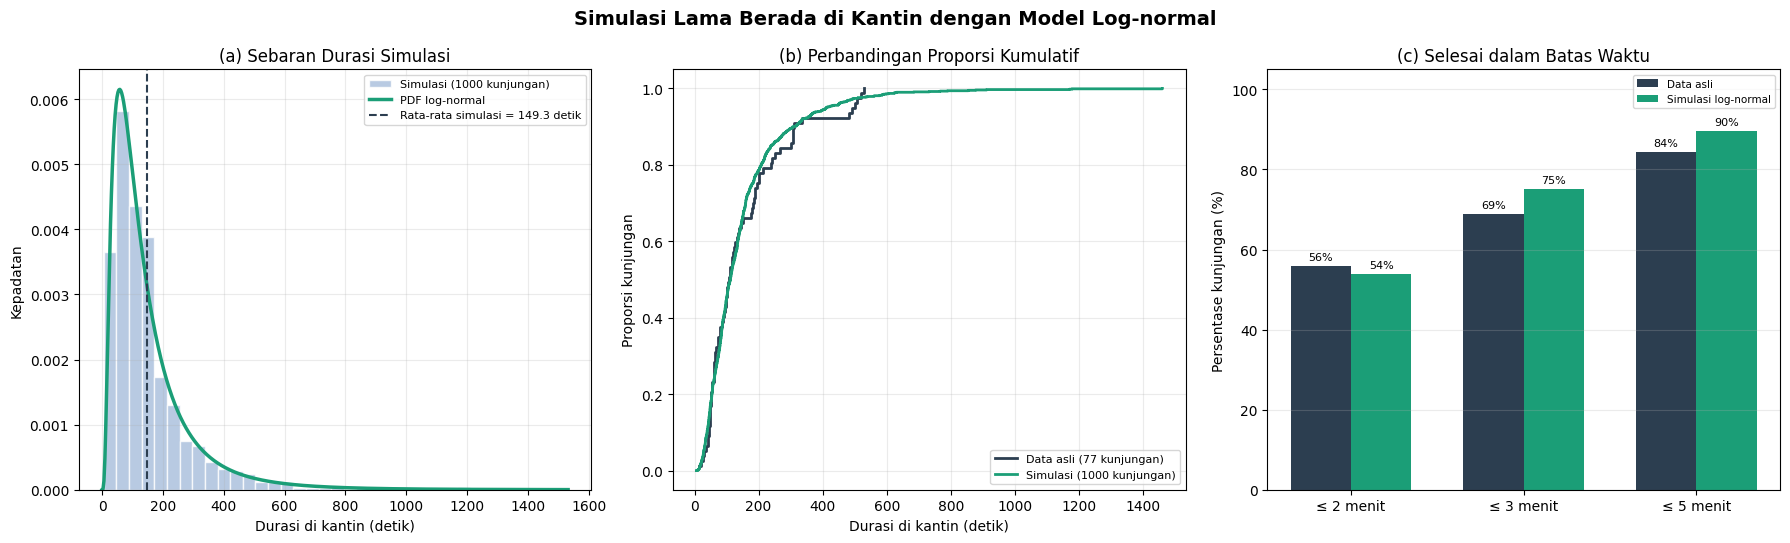

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# (a) Sebaran durasi simulasi dibanding PDF log-normal
ax = axes[0]
ax.hist(durasi_sim, bins=35, density=True, color="#a6bddb",
        edgecolor="white", alpha=0.8, label=f"Simulasi ({n_sim} kunjungan)")
x_sim = np.linspace(0, max(durasi_sim.max(), x_data.max()) * 1.05, 500)
ax.plot(x_sim, stats.lognorm.pdf(x_sim, s=shape_logn, loc=loc_logn, scale=scale_logn),
        color="#1b9e77", lw=2.5, label="PDF log-normal")
ax.axvline(durasi_sim.mean(), color="#2c3e50", ls="--", lw=1.5,
           label=f"Rata-rata simulasi = {durasi_sim.mean():.1f} detik")
ax.set_title("(a) Sebaran Durasi Simulasi")
ax.set_xlabel("Durasi di kantin (detik)")
ax.set_ylabel("Kepadatan")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

# (b) ECDF data asli dan simulasi
ax = axes[1]
for data, label, color in [
    (df["Durasi"].to_numpy(), "Data asli (77 kunjungan)", "#2c3e50"),
    (durasi_sim, f"Simulasi ({n_sim} kunjungan)", "#1b9e77"),
]:
    urut = np.sort(data)
    proporsi = np.arange(1, len(urut) + 1) / len(urut)
    ax.step(urut, proporsi, where="post", color=color, lw=2, label=label)
ax.set_title("(b) Perbandingan Proporsi Kumulatif")
ax.set_xlabel("Durasi di kantin (detik)")
ax.set_ylabel("Proporsi kunjungan")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

# (c) Proporsi selesai dalam 2, 3, dan 5 menit
ax = axes[2]
kategori = ["≤ 2 menit", "≤ 3 menit", "≤ 5 menit"]
batas_waktu = [120, 180, 300]
persen_asli = [(df["Durasi"] <= b).mean() * 100 for b in batas_waktu]
persen_sim = [(durasi_sim <= b).mean() * 100 for b in batas_waktu]
posisi = np.arange(len(kategori))
lebar = 0.35
ax.bar(posisi - lebar / 2, persen_asli, lebar, color="#2c3e50", label="Data asli")
ax.bar(posisi + lebar / 2, persen_sim, lebar, color="#1b9e77", label="Simulasi log-normal")
for p, nilai in zip(posisi - lebar / 2, persen_asli):
    ax.text(p, nilai + 1.5, f"{nilai:.0f}%", ha="center", fontsize=8)
for p, nilai in zip(posisi + lebar / 2, persen_sim):
    ax.text(p, nilai + 1.5, f"{nilai:.0f}%", ha="center", fontsize=8)
ax.set_xticks(posisi, kategori)
ax.set_ylim(0, 105)
ax.set_title("(c) Selesai dalam Batas Waktu")
ax.set_ylabel("Persentase kunjungan (%)")
ax.legend(fontsize=7.5)
ax.grid(axis="y", alpha=0.25)

fig.suptitle("Simulasi Lama Berada di Kantin dengan Model Log-normal", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

### Membaca Hasil Simulasi Log-normal

- **Bandingkan pusat dan sebaran**, bukan angka tunggal saja: rata-rata dan median simulasi semestinya berada dalam kisaran yang masuk akal terhadap data asli, sedangkan maksimum simulasi dapat jauh lebih tinggi karena model memiliki ekor kanan.
- **Proporsi kunjungan singkat** (selesai dalam 2, 3, dan 5 menit) menjadi pemeriksaan tambahan untuk melihat apakah model mengulang pola utama data.
- **Simulasi bukan data observasi baru.** Hasil 1.000 kunjungan menggambarkan konsekuensi model yang dipilih; nilai maksimum yang tinggi tidak berarti durasi tersebut pasti terjadi di lapangan.

Simulasi ini hanya membangkitkan **lama kunjungan**, bukan waktu kedatangan. Untuk memperkirakan jam ramai, jumlah orang bersamaan, atau panjang antrean, perlu ditambahkan waktu kedatangan dan waktu mulai/selesai pelayanan.

## Analisis Menurut Hari dan Jam

Jumlah catatan belum seimbang antar hari dan jam, sehingga perbandingan berikut menggambarkan pola sampel, bukan volume kedatangan. Kode ini merangkum durasi menurut hari dan jam, jumlah catatan tiap kombinasi, serta sebaran kunjungan panjang dan pencilan.


In [11]:
def ringkasan_kelompok(kolom):
    tabel = df.groupby(kolom).agg(
        Jumlah=("Durasi", "count"),
        Rata_rata=("Durasi", "mean"),
        Median=("Durasi", "median"),
        Maksimum=("Durasi", "max"),
        Persen_2_menit=("Durasi", lambda s: (s <= 120).mean() * 100),
        Persen_3_menit=("Durasi", lambda s: (s <= 180).mean() * 100),
        Persen_5_menit=("Durasi", lambda s: (s <= 300).mean() * 100),
        Lebih_5_menit=("Durasi", lambda s: (s > 300).sum()),
    )
    tabel.columns = [
        "Jumlah", "Rata-rata (dtk)", "Median (dtk)", "Maks (dtk)",
        "≤ 2 mnt (%)", "≤ 3 mnt (%)", "≤ 5 mnt (%)", "> 5 mnt",
    ]
    return tabel.round(2)


print("=== Ringkasan menurut hari ===")
print(ringkasan_kelompok("Hari").to_string())

print("\n=== Ringkasan menurut jam ===")
print(ringkasan_kelompok("Waktu").to_string())

print("\n=== Jumlah catatan per hari dan jam ===")
print(pd.crosstab(df["Hari"], df["Waktu"], margins=True, margins_name="Total"))

print("\n=== Kunjungan > 5 menit per hari dan jam ===")
print(pd.crosstab(
    df.loc[df["Durasi"] > 300, "Hari"],
    df.loc[df["Durasi"] > 300, "Waktu"],
    margins=True,
    margins_name="Total",
))

print("\n=== Pencilan IQR (durasi > 6 menit 36 detik) ===")
print(
    df.loc[df["Durasi"] > batas_wajar]
    .sort_values("Durasi", ascending=False)
    .to_string(index=False)
)


=== Ringkasan menurut hari ===
        Jumlah  Rata-rata (dtk)  Median (dtk)  Maks (dtk)  ≤ 2 mnt (%)  ≤ 3 mnt (%)  ≤ 5 mnt (%)  > 5 mnt
Hari                                                                                                     
Jumat        5           156.40          66.0         508        80.00        80.00        80.00        1
Kamis       41           183.98         137.0         530        39.02        60.98        78.05        9
Selasa      25           126.92          80.0         482        68.00        72.00        92.00        2
Senin        6            50.17          46.0         103       100.00       100.00       100.00        0

=== Ringkasan menurut jam ===
        Jumlah  Rata-rata (dtk)  Median (dtk)  Maks (dtk)  ≤ 2 mnt (%)  ≤ 3 mnt (%)  ≤ 5 mnt (%)  > 5 mnt
Waktu                                                                                                    
JAM 10      35           127.71          99.0         530        65.71        74.29       